In [96]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, OneHotEncoder

from sklearn import set_config
set_config(transform_output="pandas")


# Transformation du dataset en format numerique

## Tips dataset

In [2]:
tips_df = sns.load_dataset('tips') #tips

print(tips_df.info())
print(tips_df.nunique())
tips_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
total_bill    229
tip           123
sex             2
smoker          2
day             4
time            2
size            6
dtype: int64


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [76]:
encoder_onehot = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
tips_df_encoder = tips_df.copy()
cat_col = tips_df.select_dtypes(include=['category', 'object']).columns
print(cat_col)

encoder_onehot.fit_transform(tips_df[cat_col])

# cat_col_bin = cat_col.drop('day')
# res = encoder_onehot.fit_transform(tips_df[cat_col_bin])
# for i, col in enumerate(cat_col_bin):
#     tips_df_encoder[col] = res[:, i]

# res = encoder_onehot.fit_transform(tips_df[['day']], tips_df['day'].unique())

# for i, day in enumerate(tips_df['day'].unique()[:-1]):
#     tips_df_encoder[day] = res[:, i]
#tips_df_encoder.head()

Index(['sex', 'smoker', 'day', 'time'], dtype='str')


,sex_Male,smoker_Yes,day_Sat,day_Sun,day_Thur,time_Lunch
0,0.0,0.0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...
239,1.0,0.0,1.0,0.0,0.0,0.0
240,0.0,1.0,1.0,0.0,0.0,0.0
241,1.0,1.0,1.0,0.0,0.0,0.0
242,1.0,0.0,1.0,0.0,0.0,0.0


## Penguins Dataset

In [77]:
penguin_df = sns.load_dataset('penguins') #species

print(penguin_df.info())
print(penguin_df.nunique())
penguin_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
None
species                3
island                 3
bill_length_mm       164
bill_depth_mm         80
flipper_length_mm     55
body_mass_g           94
sex                    2
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [95]:
label_encoder = LabelEncoder()
penguin_df = penguin_df.dropna()
penguin_encoding = penguin_df.copy()

feature_cat = penguin_df.select_dtypes(include=[str]).columns

label = 'species'
feature_cat = feature_cat.drop(label)

island = list(penguin_df['island'].unique())
sex = list(penguin_df['sex'].unique())
res = encoder_onehot.fit_transform(penguin_df[feature_cat],
                                   [*island, *sex] )


res[label] = label_encoder.fit_transform(penguin_df[label]) 

penguin_encoding[res.columns] = res
penguin_encoding.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,island_Dream,island_Torgersen,sex_Male
0,0,Torgersen,39.1,18.7,181.0,3750.0,Male,0.0,1.0,1.0
1,0,Torgersen,39.5,17.4,186.0,3800.0,Female,0.0,1.0,0.0
2,0,Torgersen,40.3,18.0,195.0,3250.0,Female,0.0,1.0,0.0
4,0,Torgersen,36.7,19.3,193.0,3450.0,Female,0.0,1.0,0.0
5,0,Torgersen,39.3,20.6,190.0,3650.0,Male,0.0,1.0,1.0


## Fligths dataset

In [86]:
flight_df = sns.load_dataset('flights') #passengers

print(flight_df.info())
print(flight_df.nunique())
flight_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        144 non-null    int64   
 1   month       144 non-null    category
 2   passengers  144 non-null    int64   
dtypes: category(1), int64(2)
memory usage: 2.9 KB
None
year           12
month          12
passengers    118
dtype: int64


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [93]:
flight_df = flight_df.dropna()
flight_df_encoding = flight_df.copy()

feature_cat = ['month']

month = list(flight_df['month'].unique())
res = encoder_onehot.fit_transform(flight_df[feature_cat],
                                   [*month]) # or ordinalencoding

flight_df_encoding[res.columns] = res
flight_df_encoding.head()

,year,month,passengers,month_Aug,month_Dec,month_Feb,month_Jan,month_Jul,month_Jun,month_Mar,month_May,month_Nov,month_Oct,month_Sep
0,1949,Jan,112,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1949,Feb,118,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1949,Mar,132,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1949,Apr,129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1949,May,121,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Exercice df

In [29]:
exercice_df = sns.load_dataset('exercise') #pulse

print(exercice_df.info())
print(exercice_df.nunique())
exercice_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Unnamed: 0  90 non-null     int64   
 1   id          90 non-null     int64   
 2   diet        90 non-null     category
 3   pulse       90 non-null     int64   
 4   time        90 non-null     category
 5   kind        90 non-null     category
dtypes: category(3), int64(3)
memory usage: 2.9 KB
None
Unnamed: 0    90
id            30
diet           2
pulse         39
time           3
kind           3
dtype: int64


,Unnamed: 0,id,diet,pulse,time,kind
0,0,1,low fat,85,1 min,rest
1,1,1,low fat,85,15 min,rest
2,2,1,low fat,88,30 min,rest
3,3,2,low fat,90,1 min,rest
4,4,2,low fat,92,15 min,rest


In [92]:
diet = ['no fat', 'low fat']
kind = ['rest', 'walking', 'running']

ordinal_encode = OrdinalEncoder(categories=[diet, kind], handle_unknown='use_encoded_value', unknown_value=-1)
exercice_df_encoder = exercice_df.copy()
exercice_df_encoder['time'] = exercice_df['time'].apply(lambda x: x.split()[0])

feature_cat = ['diet', 'kind']
res = ordinal_encode.fit_transform(exercice_df[feature_cat])

exercice_df_encoder[res.columns] = res
exercice_df_encoder.head()

,Unnamed: 0,id,diet,pulse,time,kind
0,0,1,1.0,85,1,0.0
1,1,1,1.0,85,15,0.0
2,2,1,1.0,88,30,0.0
3,3,2,1.0,90,1,0.0
4,4,2,1.0,92,15,0.0


## Taxis Df

Toutes nos variables semblent etre nominales. Il convient donc d'utiliser un encodage OneHot. Cependant, les tres grans nombre de catégories dans `pickup_zone`et `drpoff_zone`rique de donner une matrice creuse qui engendrera un overfiting, un gros poids sur la RAM, et d'autres inconvenient. Dans la pratique, il convient ici d'utiliser d'autres techniques:
* Target Encoding
* Un encodage GPS 
* Un feature-engineering consistant a regrouper les zones en clusters / proximité, banlieu pourrait etre judicieux

In [51]:
taxis_df = sns.load_dataset('taxis').dropna()  #total

print(taxis_df.info())
print(taxis_df.nunique())
taxis_df.head()

<class 'pandas.DataFrame'>
Index: 6341 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6341 non-null   datetime64[us]
 1   dropoff          6341 non-null   datetime64[us]
 2   passengers       6341 non-null   int64         
 3   distance         6341 non-null   float64       
 4   fare             6341 non-null   float64       
 5   tip              6341 non-null   float64       
 6   tolls            6341 non-null   float64       
 7   total            6341 non-null   float64       
 8   color            6341 non-null   str           
 9   payment          6341 non-null   str           
 10  pickup_zone      6341 non-null   str           
 11  dropoff_zone     6341 non-null   str           
 12  pickup_borough   6341 non-null   str           
 13  dropoff_borough  6341 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)
memor

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


<Axes: xlabel='dropoff_zone', ylabel='dropoff_borough'>

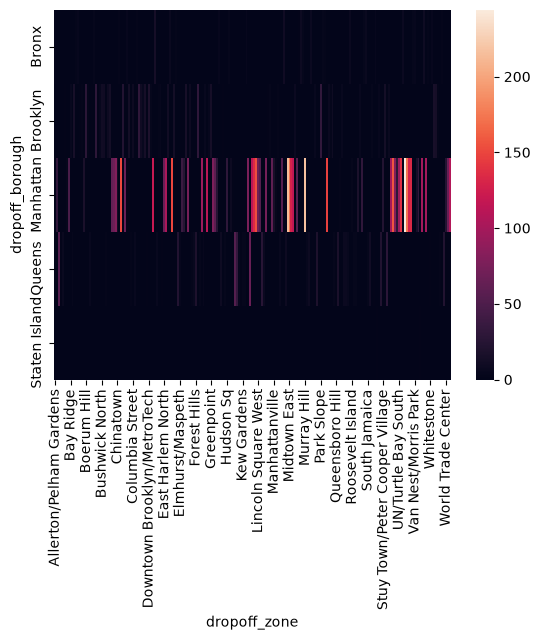

In [98]:
sns.heatmap(pd.crosstab(taxis_df['dropoff_borough'], taxis_df['dropoff_zone']))

In [100]:
unique_pairs = taxis_df[['pickup_borough', 'pickup_zone']].drop_duplicates()
unique_pairs.groupby('pickup_zone')['pickup_borough'].unique()

pickup_zone
Allerton/Pelham Gardens        [Bronx]
Alphabet City              [Manhattan]
Astoria                       [Queens]
Auburndale                    [Queens]
Battery Park               [Manhattan]
                              ...     
Woodlawn/Wakefield             [Bronx]
Woodside                      [Queens]
World Trade Center         [Manhattan]
Yorkville East             [Manhattan]
Yorkville West             [Manhattan]
Name: pickup_borough, Length: 194, dtype: object